In [1]:
from transformers import BertTokenizerFast, BertForTokenClassification, Trainer, TrainingArguments, DataCollatorForTokenClassification, AutoTokenizer, AutoModelForTokenClassification
from datasets import load_dataset, Dataset, DatasetDict, load_from_disk

import os
import random
import evaluate
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

folder_path = "dataset_conll/"

## Preprocessing

In [2]:
from datasets import Dataset

def read_conll(path):
    tokens, tags = [], []

    with open(path, "r", encoding="utf-8") as f:
        # Loop every line
        for line in f:
            
            # Skip newline
            if line.strip() == "":
                continue
            
            # Split tokens and tags e.g -> Designer B-ROLE -> ['Designer', 'B-ROLE']
            splits = line.strip().split()
            
            # Skip weird lines e.g " O", where the expected lines e.g "Designer B-ROLE"
            if len(splits) < 2:
                continue
            
            # word = 'Designer', tag = 'B-ROLE'
            word, tag = splits[0], splits[-1]
            tokens.append(word)
            tags.append(tag)

    # Make sure both token and tags has same length
    assert len(tokens) == len(tags), f"Token-label mismatch: {len(tokens)} vs {len(tags)}"

    return tokens, tags


In [3]:
tokens, tags = read_conll("dataset_conll/CV_1.conll")

In [4]:
print(tokens[:10])
print(tags[:10])

['FLORAL', 'DESIGNER', 'Highlights', 'Inventory', 'control', 'Employee', 'scheduling', 'Cash', 'handling', 'and']
['B-EXPERIENCE', 'I-EXPERIENCE', 'O', 'B-SKILL', 'I-SKILL', 'B-SKILL', 'I-SKILL', 'B-SKILL', 'I-SKILL', 'I-SKILL']


In [5]:
def load_all_cv(folder_path, train_ratio=0.7, val_ratio=0.15, seed=1):
    """Merge all documents in the folder and split into train/val/test"""
    random.seed(seed)

    data = []
    
    # Get all documents
    all_files = [f for f in os.listdir(folder_path) if f.endswith(".conll")]
    print(f"Total CV loaded: {len(all_files)}")
    print("======================================================")

    # Loop every document
    for i, filename in enumerate(sorted(all_files)):
        path = os.path.join(folder_path, filename)
        tokens, tags = read_conll(path)

        # Append to data (represent each document)
        data.append({
            "id": i,
            "doc_id": filename.replace(".conll", ""),
            "tokens": tokens,
            "ner_tags": tags
        })

    # Split by each CV, not sentence
    random.shuffle(data)
    n_total = len(data)
    n_train = int(train_ratio * n_total)
    n_val = int(val_ratio * n_total)

    train_data = data[:n_train]
    val_data = data[n_train:n_train + n_val]
    test_data = data[n_train + n_val:]
    
    print("Train data:", len(train_data))
    print("Val data  :", len(val_data))
    print("Test data :", len(test_data))
    print("======================================================")

    # Refactor to HuggingFace Dataset format
    dataset = DatasetDict({
        "train": Dataset.from_list(train_data),
        "validation": Dataset.from_list(val_data),
        "test": Dataset.from_list(test_data)
    })
    return dataset

In [6]:
dataset = load_all_cv(folder_path)
dataset

Total CV loaded: 513
Train data: 359
Val data  : 76
Test data : 78


DatasetDict({
    train: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 359
    })
    validation: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 76
    })
    test: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 78
    })
})

In [7]:
print(dataset["train"][0])

{'id': 80, 'doc_id': 'CV_171', 'tokens': ['PRESENTATION', 'DESIGNER', 'Summary', 'Customer', 'Service', 'and', 'Retail', 'Associate', '.', 'Specializes', 'in', 'Design', 'and', 'technology', ',', 'with', 'a', 'particular', 'talent', 'for', 'building', 'a', 'solid', 'customer', 'base', '.', 'Team-', 'oriented', ',', 'working', 'well', 'in', 'a', 'collaborative', 'environment', ',', 'yet', 'thrives', 'on', 'personal', 'sales', 'achievements', 'Highlights', 'InfoGraphics', 'Person', 'of', 'the', 'Quater', '(', '2014', ')', 'MTN', 'Yello', 'Star', 'Award', 'Person', 'of', 'the', 'Quater', '.', 'Customer', 'Care', 'Satisfaction', 'Training', 'Retail', 'and', 'Sales', 'Adobe', 'Photoshop', '(', 'Mock', 'ups', 'and', 'Prototype', ')', 'Axure', 'RP', '(', 'Wireframes', 'and', 'Interactive', 'Prototypes', ')', 'Adobe', 'Illustrator', '(', 'Vector', 'Assets', ')', 'Adobe', 'Dreamweaver', '(', 'Creation', 'of', 'mobile', 'sites', 'and', 'Websites', ')', 'HTML', 'and', 'CSS', '.', 'Adobe', 'Creati

## EDA

=== TRAIN ===
Average word count: 213.3 tokens
Min: 54, Max: 486
------------------------
=== VALIDATION ===
Average word count: 200.9 tokens
Min: 52, Max: 479
------------------------
=== TEST ===
Average word count: 202.3 tokens
Min: 65, Max: 403
------------------------


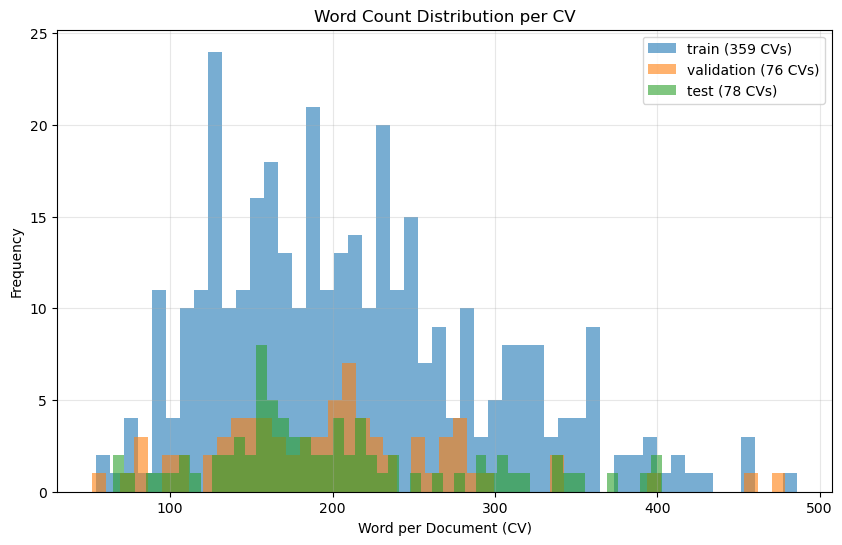

In [8]:
def plot_word_distribution(dataset):
    """Count word distribution per CV"""
    subsets = ["train", "validation", "test"]
    plt.figure(figsize=(10, 6))

    for subset in subsets:

        # Get token length
        lengths = [len(x["tokens"]) for x in dataset[subset]]
        
        # Plot histogram
        plt.hist(lengths, bins=50, alpha=0.6, label=f"{subset} ({len(lengths)} CVs)")

        # Logging info
        print(f"=== {subset.upper()} ===")
        print(f"Average word count: {sum(lengths)/len(lengths):.1f} tokens")
        print(f"Min: {min(lengths)}, Max: {max(lengths)}")
        print("------------------------")

    plt.title("Word Count Distribution per CV")
    plt.xlabel("Word per Document (CV)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_word_distribution(dataset)


=== TRAIN ===
         Tag  Avg tag per CV
     B-SKILL       14.860724
I-EXPERIENCE       12.977716
     I-SKILL       11.690808
 I-EDUCATION        7.011142
B-EXPERIENCE        5.342618
 B-EDUCATION        1.398329


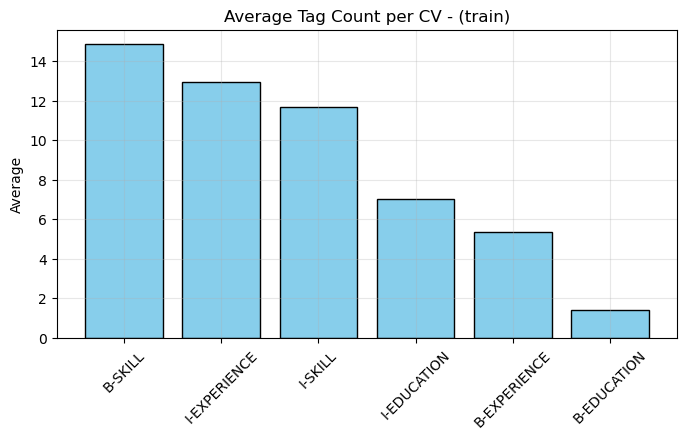


=== VALIDATION ===
         Tag  Avg tag per CV
     B-SKILL       13.026316
I-EXPERIENCE       12.684211
     I-SKILL        9.750000
 I-EDUCATION        6.342105
B-EXPERIENCE        5.144737
 B-EDUCATION        1.250000


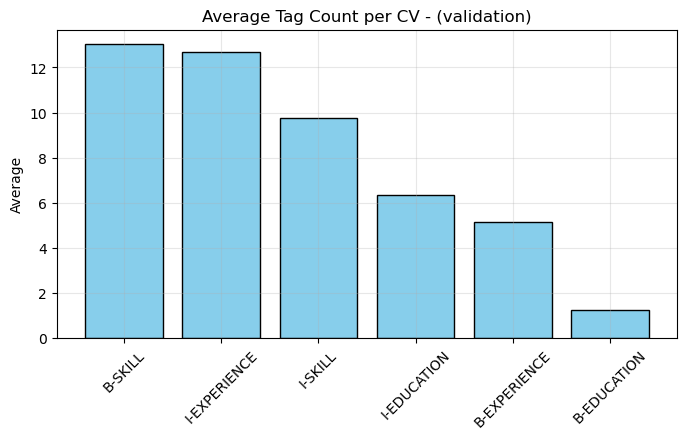


=== TEST ===
         Tag  Avg tag per CV
     B-SKILL       14.307692
I-EXPERIENCE       11.858974
     I-SKILL       10.012821
 I-EDUCATION        8.038462
B-EXPERIENCE        5.217949
 B-EDUCATION        1.564103


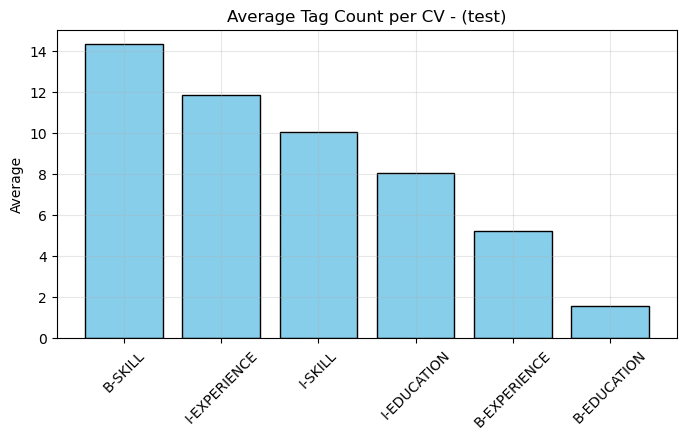

In [9]:
def average_tag_counts_per_cv(dataset):
    """Count average tag counts per CV"""
    subsets = ["train", "validation", "test"]

    # Loop for each dataset (train/test/val)
    for subset in subsets:
        
        print(f"\n=== {subset.upper()} ===")
        tag_totals = defaultdict(int) # automated add key value pair if key not exist
        cv_count = len(dataset[subset]) # total CV per subset

        # Loop each CV
        for cv in dataset[subset]:
            
            tags = cv["ner_tags"]
            b_tag = [t for t in tags if t.startswith("B-") or t.startswith("I-")] # Store every tag start with B-
            counts = Counter(b_tag) # Count every tag per label
            
            # For every tag and number count, fit into tag_totals dictionary
            for tag, count in counts.items():
                tag_totals[tag] += count
        
        # Calculate avg tags (all tags count / total CV)
        avg_counts = {tag: tag_totals[tag] / cv_count for tag in tag_totals}

        # Convert into table
        df = pd.DataFrame(sorted(avg_counts.items(), key=lambda x: -x[1]), columns=["Tag", "Avg tag per CV"])
        print(df.to_string(index=False))

        # Plot bar chart
        plt.figure(figsize=(8, 4))
        plt.bar(df["Tag"], df["Avg tag per CV"], color="skyblue", edgecolor="black")
        plt.title(f"Average Tag Count per CV - ({subset})")
        plt.ylabel("Average")
        plt.xticks(rotation=45)
        plt.grid(alpha=0.3)
        plt.show()
        
average_tag_counts_per_cv(dataset)

In [10]:
def top_words_per_label(dataset, top_n=10):
    subsets = ["train", "validation", "test"]

    # Loop for each subsets
    for subset in subsets:
        print(f"\n=== {subset.upper()} ===")

        # Set dictionary for each tag
        tag_word_counter = defaultdict(Counter)

        # Loop dataset
        for row in dataset[subset]:
            tokens = row["tokens"]
            tags = row["ner_tags"]

            for token, tag in zip(tokens, tags):
                if tag != "O":  
                    tag_word_counter[tag][token] += 1

        # Tampilkan hasil
        for tag, counter in tag_word_counter.items():
            print(f"\nTop words untuk tag {tag}:")
            for word, freq in counter.most_common(top_n):
                print(f"  {word:<20} {freq}")
                
top_words_per_label(dataset, 5)


=== TRAIN ===

Top words untuk tag B-EXPERIENCE:
  Information          81
  Director             65
  Senior               60
  Engineering          53
  ENGINEERING          47

Top words untuk tag I-EXPERIENCE:
  Manager              219
  /                    166
  Designer             162
  Technology           107
  Engineer             98

Top words untuk tag B-SKILL:
  Microsoft            287
  Adobe                121
  Windows              118
  Project              102
  Excel                94

Top words untuk tag I-SKILL:
  management           219
  Management           179
  Office               145
  and                  139
  -                    102

Top words untuk tag B-EDUCATION:
  Bachelor             172
  Master               69
  Associate            57
  High                 31
  B.S                  20

Top words untuk tag I-EDUCATION:
  :                    381
  of                   318
  Science              211
  Arts                 109
  Engineering  